In [13]:
import os
import sys

# Dynamically add the Conda environment's Library/bin folder to PATH
env_bin = os.path.join(sys.prefix, "Library", "bin")
if env_bin not in os.environ["PATH"]:
    os.environ["PATH"] = env_bin + os.path.pathsep + os.environ["PATH"]

import pygmt
#pygmt.show_versions()
import pandas as pd
import numpy as np

In [14]:
import numpy as np
import pandas as pd
from openquake.hazardlib.geo import Point, Line, SimpleFaultSurface, Mesh

niigata_df = pd.read_csv('niigata.csv', sep=r'\s+|\t|,', engine='python')
event_row = niigata_df.iloc[0]
event = {
    'event_name': str(event_row['event_name']),
    'longitude': float(event_row['longitude']), # 138.779
    'latitude': float(event_row['latitude']),   # 37.226
    'depth': float(event_row['depth']),         # 16.0 km
    'strike': float(event_row['strike']),       # 211.0 deg
    'dip': float(event_row['dip']),             # 54.0 deg
    'rake': float(event_row['rake']),           # 92.0 deg
    'magnitude': float(event_row['magnitude'])   # 6.53
}

lon_epi = event['longitude']
lat_epi = event['latitude']
depth_epi = event['depth']
eq_point = Point(lon_epi, lat_epi, depth_epi)

print(f"Event: {event['event_name']}, Magnitude: {event['magnitude']}, Location: ({lon_epi}, {lat_epi}), Depth: {depth_epi} km")

Event: Nigata, Magnitude: 6.53, Location: (138.779, 37.226), Depth: 16.0 km


In [15]:
# Read station information from the NGA-West2 flatfile
nga_file = 'NGA_West2_Flatfile_RotD50_d005_public_version.xlsx'

df_nga = pd.read_excel(nga_file, sheet_name=0)
df_niigata = pd.DataFrame()
df_niigata = df_nga[df_nga['Earthquake Name'].astype(str).str.contains('Niigata, Japan', case=False, na=False)].copy()

# Will load everything I need for question 2
df_stations = pd.DataFrame()
df_stations['Station Name'] = df_niigata['Station Name'].values
df_stations['lon'] = df_niigata['Station Longitude'].values
df_stations['lat'] = df_niigata['Station Latitude'].values
df_stations['PGA'] = df_niigata['PGA (g)'].values
df_stations['NEHRP class'] = df_niigata['Preferred NEHRP Based on Vs30'].values
df_stations['Vs30'] = df_niigata['Vs30 (m/s) selected for analysis'].values
df_stations['Z1'] = df_niigata['Northern CA/Southern CA - H11 Z1 (m)'].values
df_stations['Rjb'] = df_niigata['Joyner-Boore Dist. (km)'].values
depth_site = np.zeros_like(df_stations['lon'] , dtype=float)

# Output Summary Table
df_stations_output = pd.DataFrame({
    'Station Name': df_stations['Station Name'],
    'PGA (g)': df_stations['PGA'],
    'NEHRP Classification': df_stations['NEHRP class'],
    'Vs30 (m/s)': df_stations['Vs30'],
    'Z1 (m)': df_stations['Z1'],
    'Station_Lat': df_stations['lat'],
    'Station_Lon': df_stations['lon'],
    'NGA_Flatfile_Rjb_km': df_stations['Rjb'],
})

site_mesh = Mesh(
    np.array(df_stations['lon'].values), 
    np.array(df_stations['lat'].values), 
    np.array(depth_site)
) 


c:\Users\gabyz\anaconda3\envs\openquake\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


To compute the distance between the hypocenter ($R_{hypo}$) and each point of our station `Mesh()`, we can use the `distance_to_mesh()` method of the `Point()` object with the attribute `with_depths` set to `True`. If we are interested in the distance between the projections of the points ($R_{epi}$), we assign the attribute `with_depths` set to `False`:

In [16]:
df_stations_output['r_epi_openquake'] = eq_point.distance_to_mesh(site_mesh, with_depths=False) #projected on surface
df_stations_output['r_hypo_openquake'] = eq_point.distance_to_mesh(site_mesh, with_depths=True) #considering depth of points, hypocentral distance


In [17]:
import json
import geopandas as gpd
import io

# Reading as a GeoDataFrame to visualize the rupture geometry
rupture = gpd.read_file("rupture_niigata.json")

# Exploring the rupture geometry
with open('rupture_niigata.json', 'r') as file:
    rupture_json = json.load(file)

rupture_json

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'geometry': {'type': 'MultiPolygon',
    'coordinates': [[[[139.02, 37.38, 5.0],
       [138.87, 37.19, 5.0],
       [138.8, 37.22, 15.0],
       [138.95, 37.42, 15.0],
       [139.02, 37.38, 5.0]]]]},
   'properties': {'rupture type': 'rupture extent'}}],
 'metadata': {'depth': 16.0,
  'lon': 138.779,
  'netid': 'us',
  'mag': 6.6,
  'id': 'usp000d6vk',
  'lat': 37.226,
  'rake': 0.0,
  'time': '2004-10-23T08:56:00.000000Z',
  'mech': 'ALL',
  'locstring': 'near the west coast of Honshu, Japan',
  'network': 'USGS National Earthquake Information Center, PDE',
  'reference': 'Joshi, A., and K. Mohan (2008). Simulation of accelerograms from simplified deterministic approach for the 23rd October 2004 Niigata-ken Chuetsu, Japan earthquake. J. Seismology 12, 1, 35-51.',
  'productcode': 'usp000d6vk'}}

In [18]:
# Sorting into desired order
from openquake.hazardlib.geo.mesh import RectangularMesh
from openquake.hazardlib.geo.surface import PlanarSurface, SimpleFaultSurface
polygon_coordinates = rupture_json['features'][0]['geometry']['coordinates'][0][0]

# Remove negative depths from the rupture coordinates - Drop the last coordinate which is a duplicate of the first
clean_coords = [(lon, lat, abs(depth)) for lon, lat, depth in polygon_coordinates[:-1]]

# Get the midpoint index of the clean coordinates list
midpoint = len(clean_coords) // 2 

# Divide the coordinates into top and bottom traces
top_vertex = clean_coords[:midpoint]
bottom_vertex = clean_coords[midpoint:]

# Correct the strike of the bottom trace
bottom_vertex.reverse()

# Construct the array for the RectangularMesh
lons = np.array([[pt[0] for pt in top_vertex], [pt[0] for pt in bottom_vertex]])
lats = np.array([[pt[1] for pt in top_vertex], [pt[1] for pt in bottom_vertex]])
depths = np.array([[pt[2] for pt in top_vertex], [pt[2] for pt in bottom_vertex]])

# Define the SimpleFaultSurface using the RectangularMesh
fault_mesh_niigata = RectangularMesh(lons, lats, depths)
rupture_surface_niigata = SimpleFaultSurface(fault_mesh_niigata)

In [19]:
# Rrup, Rjb, and Rx distances
df_stations_output['r_rup_openquake'] = rupture_surface_niigata.get_min_distance(site_mesh)
df_stations_output['r_jb_openquake'] = rupture_surface_niigata.get_joyner_boore_distance(site_mesh)
df_stations_output['rx_openquake'] = rupture_surface_niigata.get_rx_distance(site_mesh)
#Ztor 
df_stations_output['Ztor_openquake'] = rupture_surface_niigata.get_top_edge_depth()
df_stations_output
df_stations_output.to_csv('niigata_input.csv', index=False)

C:\Users\gabyz\AppData\Local\Temp\ipykernel_135592\935375395.py:35: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0,310)
C:\Users\gabyz\AppData\Local\Temp\ipykernel_135592\935375395.py:36: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1.5)
C:\Users\gabyz\AppData\Local\Temp\ipykernel_135592\935375395.py:60: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0,310)
C:\Users\gabyz\AppData\Local\Temp\ipykernel_135592\935375395.py:61: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1.5)


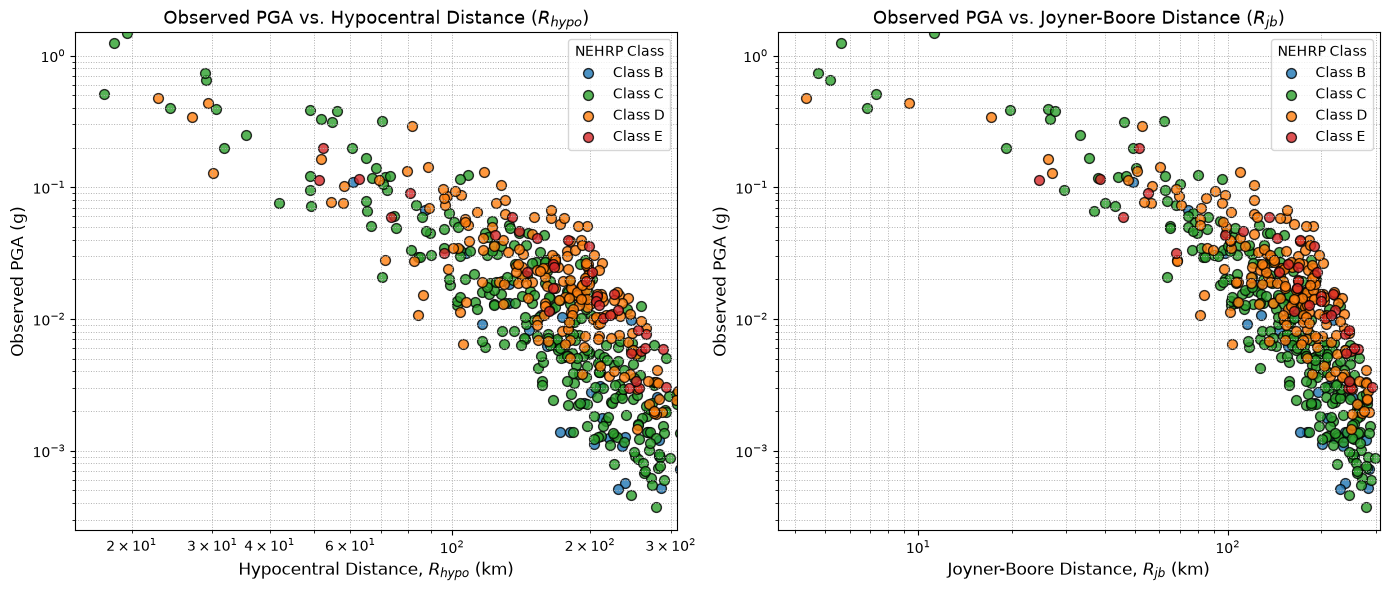

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define NEHRP Site Class colors
nehrp_colors = {
    'B': '#1f77b4',  # Blue (Rock)
    'C': '#2ca02c',  # Green (Hard/Dense Soil)
    'D': '#ff7f0e',  # Orange (Stiff Soil)
    'E': '#d62728'   # Red (Soft Soil)
}

plt.figure(figsize=(14, 6))

# PGA vs Rupture / Hypocentral Distance (R_rup)
plt.subplot(1, 2, 1)
for nehrp_class, color in nehrp_colors.items():
    subset = df_stations_output[df_stations_output['NEHRP Classification'] == nehrp_class]
    if not subset.empty:
        plt.scatter(
            subset['r_hypo_openquake'], 
            subset['PGA (g)'], 
            color=color, 
            label=f'Class {nehrp_class}', 
            alpha=0.8, 
            edgecolors='k', 
            s=50
        )

plt.loglog()  
plt.xlabel('Hypocentral Distance, $R_{hypo}$ (km)', fontsize=12)
plt.ylabel('Observed PGA (g)', fontsize=12)
plt.title('Observed PGA vs. Hypocentral Distance ($R_{hypo}$)', fontsize=13)
plt.grid(True, which='both', linestyle=':', linewidth=0.7)
plt.legend(title='NEHRP Class', fontsize=10)
plt.xlim(0,310)  
plt.ylim(0, 1.5)  


# PGA vs Joyner-Boore Distance (R_jb)
plt.subplot(1, 2, 2)
for nehrp_class, color in nehrp_colors.items():
    subset = df_stations_output[df_stations_output['NEHRP Classification'] == nehrp_class]
    if not subset.empty:
        plt.scatter(
            subset['r_jb_openquake'], 
            subset['PGA (g)'], 
            color=color, 
            label=f'Class {nehrp_class}', 
            alpha=0.8, 
            edgecolors='k', 
            s=50
        )

plt.loglog()  
plt.xlabel('Joyner-Boore Distance, $R_{jb}$ (km)', fontsize=12)
plt.ylabel('Observed PGA (g)', fontsize=12)
plt.title('Observed PGA vs. Joyner-Boore Distance ($R_{jb}$)', fontsize=13)
plt.grid(True, which='both', linestyle=':', linewidth=0.7)
plt.legend(title='NEHRP Class', fontsize=10)
plt.xlim(0,310)  
plt.ylim(0, 1.5)

plt.tight_layout()
plt.savefig('PGA_vs_Distance_NEHRP.png', dpi=300)
plt.show()

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from openquake.hazardlib.gsim.boore_2014 import BooreEtAl2014
from openquake.hazardlib.gsim.chiou_youngs_2014 import ChiouYoungs2014
from openquake.hazardlib.imt import PGA, PGV, SA
from openquake.hazardlib.contexts import simple_cmaker


# Context Setup & Intensity Measure Definitions
n = len(df_stations_output)
mag = np.full(n, event['magnitude'])

periods = [0.02, 0.04, 0.08, 0.1, 0.2, 0.4, 0.8, 1.0, 2.0, 3.0]
imts = [SA(T) for T in periods]
imt_strings = [str(imt) for imt in imts]
n = len(df_stations_output)

#  Boore et al. (2014) - BSSA14
gsim_bea = BooreEtAl2014()
cmaker_bea = simple_cmaker([gsim_bea], imt_strings)

ctx = cmaker_bea.new_ctx(n)

ctx["mag"] = event['magnitude'] 
ctx["rake"] = event['rake']
ctx["rjb"] = df_stations_output['r_jb_openquake']
ctx["vs30"] = df_stations_output['Vs30 (m/s)']
print(ctx[:10])

means, sigmas, taus, phis = cmaker_bea.get_mean_stds([ctx])

predicted_bssa14 = []
for imt_idx, imt_str in enumerate(imt_strings):
    df_imt = pd.DataFrame({
        'station': df_stations_output['Station Name'],
        'rjb': df_stations_output['r_jb_openquake'],
        'Vs30': df_stations_output['Vs30 (m/s)'],
        'imt': imt_str,
        'mean_log': means[0][imt_idx],
        'mean_g': np.exp(means[0][imt_idx]),
        'sigma': sigmas[0][imt_idx],
        'tau': taus[0][imt_idx],
        'phi': phis[0][imt_idx]
    })
    predicted_bssa14.append(df_imt)

df_BSSA14 = pd.concat(predicted_bssa14, ignore_index=True)
df_BSSA14.to_csv('BSSA14.csv', index=False)

df_BSSA14_wide = df_BSSA14.pivot(
    index=['station', 'rjb', 'Vs30'], 
    columns='imt', 
    values='mean_g'
).reset_index()

df_BSSA14_wide.to_csv('BSSA14_wide.csv', index=False)
print("Saved Boore et al. (2014) results to BSSA14.csv and BSSA14_wide.csv")

[(6.53, 92., 133.05, 97.79514438, 0., 0, 0, 0, 0.)
 (6.53, 92., 370.4 , 80.35299684, 0., 0, 0, 0, 0.)
 (6.53, 92., 211.76, 60.47123432, 0., 0, 0, 0, 0.)
 (6.53, 92., 182.3 , 81.02714828, 0., 0, 0, 0, 0.)
 (6.53, 92., 234.27, 98.302437  , 0., 0, 0, 0, 0.)
 (6.53, 92., 615.23, 78.20641863, 0., 0, 0, 0, 0.)
 (6.53, 92., 330.61, 47.57708202, 0., 0, 0, 0, 0.)
 (6.53, 92., 697.72, 67.90643332, 0., 0, 0, 0, 0.)
 (6.53, 92., 305.54, 26.2392535 , 0., 0, 0, 0, 0.)
 (6.53, 92., 431.98, 49.20562591, 0., 0, 0, 0, 0.)]
Saved Boore et al. (2014) results to BSSA14.csv and BSSA14_wide.csv


In [22]:
df_stations_output.head()

,Station Name,PGA (g),NEHRP Classification,Vs30 (m/s),Z1 (m),Station_Lat,Station_Lon,NGA_Flatfile_Rjb_km,r_epi_openquake,r_hypo_openquake,r_rup_openquake,r_jb_openquake,rx_openquake,Ztor_openquake
0,FKS020,0.043384,E,133.05,360.0,37.5474,140.1078,101.78,122.717931,123.756578,97.884547,97.795144,-70.958107,5.0
1,FKS021,0.122900,C,370.40,220.0,37.6535,139.8633,84.17,106.882176,108.073121,80.476934,80.352997,-46.460470,5.0
2,FKS022,0.143550,D,211.76,200.0,37.6002,139.6467,64.25,87.201547,88.657260,60.653939,60.471234,-33.591268,5.0
3,FKS023,0.057119,D,182.30,300.0,37.4774,139.9294,85.01,105.457564,106.664416,81.149530,81.027148,-61.945302,5.0
4,FKS024,0.049540,D,234.27,120.0,37.3957,140.1325,102.30,121.180382,122.232095,98.390982,98.302437,-81.939728,5.0


In [23]:
# Chiou & Youngs (2014) - CY14
gsim_cy = ChiouYoungs2014()
cmaker_cy = simple_cmaker([gsim_cy], imt_strings, mags=["%2.2f" % m for m in mag])

ctx_cy = cmaker_cy.new_ctx(n)
ctx_cy["mag"] = mag
ctx_cy["dip"] = event['dip']
ctx_cy["rake"] = event['rake']
ctx_cy["ztor"] = df_stations_output['Ztor_openquake'].values
ctx_cy["rjb"] = df_stations_output['r_jb_openquake'].values
ctx_cy["rrup"] = df_stations_output['r_rup_openquake'].values
ctx_cy["rx"] = df_stations_output['rx_openquake'].values
ctx_cy["vs30"] = df_stations_output['Vs30 (m/s)'].values
ctx_cy["z1pt0"] = df_stations_output['Z1 (m)'].values

means, sigmas, taus, phis = cmaker_cy.get_mean_stds([ctx_cy])

predicted_cy14 = []
for imt_idx, imt_str in enumerate(imt_strings):
    df_imt = pd.DataFrame({
        'station': df_stations_output['Station Name'],
        'rrup': df_stations_output['r_rup_openquake'],
        'Vs30': df_stations_output['Vs30 (m/s)'],
        'imt': imt_str,
        'mean_log': means[0][imt_idx],
        'mean_g': np.exp(means[0][imt_idx]),
        'sigma': sigmas[0][imt_idx],
        'tau': taus[0][imt_idx],
        'phi': phis[0][imt_idx]
    })
    predicted_cy14.append(df_imt)

df_CY14 = pd.concat(predicted_cy14, ignore_index=True)
df_CY14.to_csv('CY14.csv', index=False)

df_CY14_wide = df_CY14.pivot(
    index=['station', 'rrup', 'Vs30'], 
    columns='imt', 
    values='mean_g'
).reset_index()

df_CY14_wide.to_csv('CY14_wide.csv', index=False)
print("Saved Chiou & Youngs (2014) results to CY14.csv and CY14_wide.csv")


Saved Chiou & Youngs (2014) results to CY14.csv and CY14_wide.csv


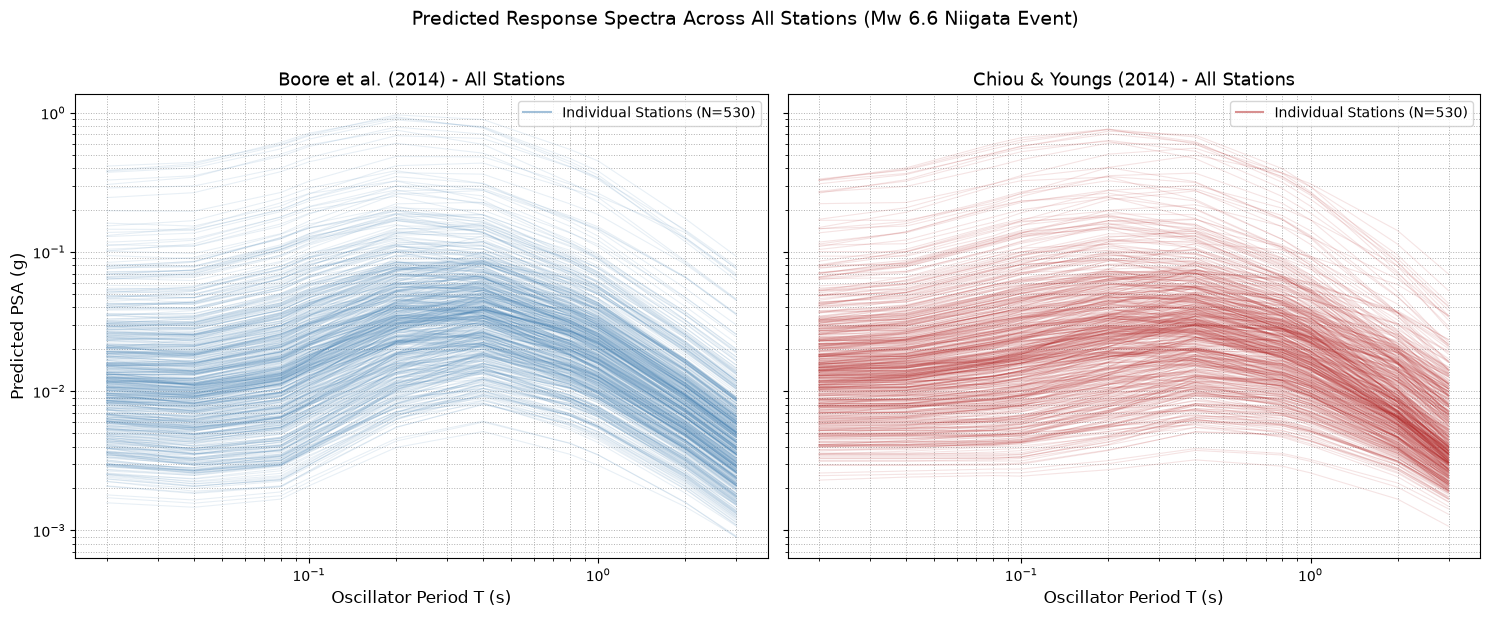

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reshape BSSA14 results
bssa14_piv = df_BSSA14.pivot(index='station', columns='imt', values='mean_g')
# Reshape CY14 results
cy14_piv = df_CY14.pivot(index='station', columns='imt', values='mean_g')

# Filter for SA periods and sort columns by numeric period value
sa_cols = [c for c in bssa14_piv.columns if c.startswith('SA(')]
sa_cols_sorted = sorted(sa_cols, key=lambda x: float(x.split('(')[1].rstrip(')')))
periods_num = [float(x.split('(')[1].rstrip(')')) for x in sa_cols_sorted]

# Extract arrays (Shape: [n_stations, n_periods])
bssa14_matrix = bssa14_piv[sa_cols_sorted].values
cy14_matrix = cy14_piv[sa_cols_sorted].values

# Calculate median and percentiles across all stations
bssa14_median = np.median(bssa14_matrix, axis=0)
bssa14_p16 = np.percentile(bssa14_matrix, 16, axis=0)
bssa14_p84 = np.percentile(bssa14_matrix, 84, axis=0)

cy14_median = np.median(cy14_matrix, axis=0)
cy14_p16 = np.percentile(cy14_matrix, 16, axis=0)
cy14_p84 = np.percentile(cy14_matrix, 84, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

#Subplot 1: Boore et al. (2014)
# Plot all individual station lines with high transparency
axes[0].plot(periods_num, bssa14_matrix.T, color='steelblue', alpha=0.12, lw=0.8)
# Dummy line for legend entry
axes[0].plot([], [], color='steelblue', alpha=0.5, label=f'Individual Stations (N={len(bssa14_piv)})')

axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Oscillator Period T (s)', fontsize=12)
axes[0].set_ylabel('Predicted PSA (g)', fontsize=12)
axes[0].set_title('Boore et al. (2014) - All Stations', fontsize=13)
axes[0].grid(True, which='both', linestyle=':', linewidth=0.7)
axes[0].legend(fontsize=10, loc='upper right')

#Subplot 2: Chiou & Youngs (2014)
axes[1].plot(periods_num, cy14_matrix.T, color='firebrick', alpha=0.12, lw=0.8)
# Dummy line for legend entry
axes[1].plot([], [], color='firebrick', alpha=0.5, label=f'Individual Stations (N={len(cy14_piv)})')

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Oscillator Period T (s)', fontsize=12)
axes[1].set_title('Chiou & Youngs (2014) - All Stations', fontsize=13)
axes[1].grid(True, which='both', linestyle=':', linewidth=0.7)
axes[1].legend(fontsize=10, loc='upper right')

plt.suptitle('Predicted Response Spectra Across All Stations (Mw 6.6 Niigata Event)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('All_Stations_GMM_Spectra.png', dpi=300, bbox_inches='tight')
plt.show()

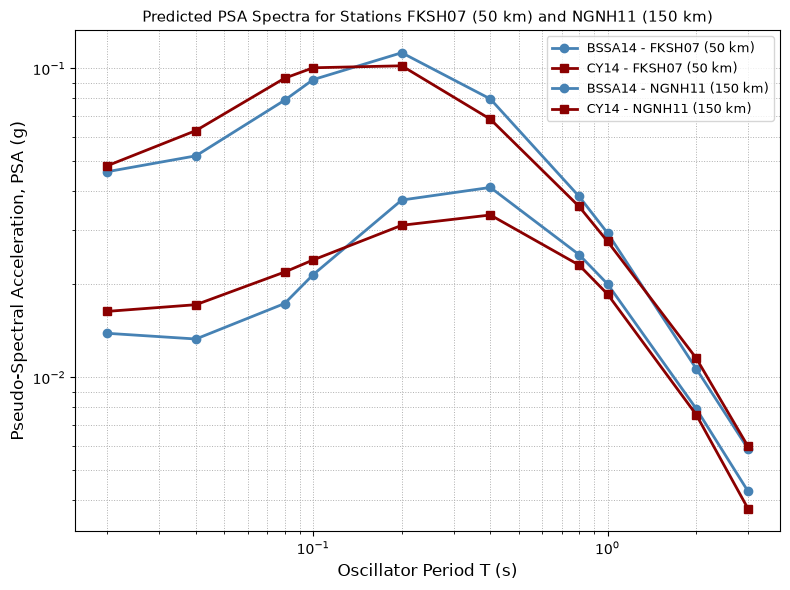

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

df_BSSA14_wide = pd.read_csv('BSSA14_wide.csv')
df_CY14_wide = pd.read_csv('CY14_wide.csv')

# Define periods and match exact SA column header names
periods = [0.02, 0.04, 0.08, 0.1, 0.2, 0.4, 0.8, 1.0, 2.0, 3.0]
sa_cols = [f"SA({T})" for T in periods]

# Extract predicted PSA vectors for FKSH07 (~50 km) and NGNH11 (~150 km)
psa_bea_50 = df_BSSA14_wide[df_BSSA14_wide['station'] == 'FKSH07'][sa_cols].values[0]
psa_cy_50  = df_CY14_wide[df_CY14_wide['station'] == 'FKSH07'][sa_cols].values[0]

psa_bea_150 = df_BSSA14_wide[df_BSSA14_wide['station'] == 'NGNH11'][sa_cols].values[0]
psa_cy_150  = df_CY14_wide[df_CY14_wide['station'] == 'NGNH11'][sa_cols].values[0]

# Response Spectrum Plotting

plt.figure(figsize=(8, 6))

# FKSH07 (~50 km) - Solid lines
plt.plot(periods, psa_bea_50, '-o', color='steelblue', lw=2, label='BSSA14 - FKSH07 (50 km)')
plt.plot(periods, psa_cy_50, '-s', color='darkred', lw=2, label='CY14 - FKSH07 (50 km)')

# NGNH11 (~150 km) - Dashed lines
plt.plot(periods, psa_bea_150, '-o', color='steelblue', lw=2, label='BSSA14 - NGNH11 (150 km)')
plt.plot(periods, psa_cy_150, '-s', color='darkred', lw=2, label='CY14 - NGNH11 (150 km)')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Oscillator Period T (s)', fontsize=12)
plt.ylabel('Pseudo-Spectral Acceleration, PSA (g)', fontsize=12)
plt.title('Predicted PSA Spectra for Stations FKSH07 (50 km) and NGNH11 (150 km)', fontsize=11)
plt.grid(True, which='both', linestyle=':', linewidth=0.7)
plt.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.savefig('GMM_PSA_FKSH07_NGNH11.png', dpi=300)
plt.show()